# Previsão temporal de surtos de dengue — versão metodologicamente revisada

Este notebook acompanha o estudo de doutorado sobre previsão de surtos de dengue em Ribeirão Preto. Cada previsão usa informações disponíveis até a semana de emissão e avalia horizontes de 4, 8, 12 e 16 semanas.

O código analítico foi organizado em `src/dengue_research` para permitir revisão, reutilização e controle de versão. O notebook documenta e executa o pipeline sem duplicar blocos por horizonte.

## Protocolo pré-especificado

- Análise principal: surto exatamente em `t+h`.
- Análise complementar: pelo menos uma semana de surto entre `t+1` e `t+h`.
- Treino: datas-alvo até 2021-12-26.
- Validação: 2022–2023.
- Teste final: 2024–2025.
- Casos entram com atraso mínimo de uma semana.
- Métrica principal: PR-AUC; operação orientada a recall mínimo de 0,80 na validação.
- O teste não escolhe features, hiperparâmetros, épocas ou limiares.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from dengue_research.pipeline import StudyConfig, load_weekly_data, audit_data, causal_endemic_channel
from dengue_research.reporting import load_results, metrics_frame, split_frame

config = StudyConfig(
    data_path=PROJECT_ROOT / 'data/dataset/processado/base_modelagem_dengue_dataset.xlsx',
    output_dir=PROJECT_ROOT / 'outputs/revisao_metodologica',
)
config

StudyConfig(data_path=PosixPath('/media/lorenzo/SSD/Projetos/ML-Dengue/data/dataset/processado/base_modelagem_dengue_dataset.xlsx'), output_dir=PosixPath('/media/lorenzo/SSD/Projetos/ML-Dengue/outputs/revisao_metodologica'), horizons=(4, 8, 12, 16), target_kinds=('exact', 'window'), case_column='n dengue', date_column='dt_pri_sem', train_end='2021-12-26', validation_start='2022-01-02', validation_end='2023-12-31', test_start='2024-01-07', test_end='2025-12-28', endemic_quantile=0.75, endemic_week_radius=2, endemic_lookback_years=5, endemic_min_years=3, persistence_weeks=3, persistence_factor=1.1, sequence_length=12, target_recall=0.8, seed=42, numpy_hidden_size=16, numpy_epochs=120, pytorch_hidden_size=32, pytorch_epochs=150, early_stopping_patience=20)

## Auditoria dos dados

A célula seguinte verifica continuidade semanal, duplicatas, valores ausentes, intervalo temporal e compatibilidade das variáveis espaciais com o alvo municipal.

In [2]:
df = load_weekly_data(config)
pd.Series(audit_data(df, config), name='valor').to_frame()

,valor
n_rows,784
n_columns,73
start,2010-12-26
end,2025-12-28
frequency,W-SUN
duplicated_dates,0
missing_values,0
infinite_numeric_values,0
case_min,6.0
case_median,126.5


## Canal endêmico causal

O limite de cada semana usa somente anos anteriores. Isso simula a informação disponível naquele momento e evita que 2024–2025 altere os rótulos do período de desenvolvimento.

In [3]:
endemic = causal_endemic_channel(df, config)
display(endemic[['endemic_threshold', 'outbreak']].dropna().head())
print('Semanas rotuladas:', endemic['outbreak'].notna().sum())
print('Semanas de surto:', int(endemic['outbreak'].fillna(0).sum()))

,endemic_threshold,outbreak
dt_pri_sem,,
2013-12-08,97.00,0.0
2013-12-15,122.75,0.0
2013-12-22,132.25,0.0
2013-12-29,210.50,0.0
2014-01-05,357.00,0.0


Semanas rotuladas: 630
Semanas de surto: 237


## Execução completa

A execução treina baselines, regressão logística, Random Forest, LSTM NumPy com BPTT completo e LSTM PyTorch. Também calcula intervalos por bootstrap, regressão de casos e explicações Captum. Para reproduzir todos os resultados, execute no terminal do projeto:

```bash
MPLCONFIGDIR=/tmp/mpl-dengue .venv/bin/python scripts/run_revised_study.py
```

In [4]:
results_path = config.output_dir / 'resultados_completos.json'
if not results_path.exists():
    raise FileNotFoundError('Execute scripts/run_revised_study.py antes desta seção.')
results = load_results(results_path)
metrics = metrics_frame(results)
splits = split_frame(results)

## Partições temporais e prevalência

,target_kind,horizon,split,n,positive,prevalence,first_issue_date,last_issue_date,first_target_date,last_target_date
0,exact,4,train,421,100,0.237530,2013-11-10,2021-11-28,2013-12-08,2021-12-26
1,exact,4,validation,105,70,0.666667,2021-12-05,2023-12-03,2022-01-02,2023-12-31
2,exact,4,test,104,67,0.644231,2023-12-10,2025-11-30,2024-01-07,2025-12-28
3,exact,8,train,421,100,0.237530,2013-10-13,2021-10-31,2013-12-08,2021-12-26
4,exact,8,validation,105,70,0.666667,2021-11-07,2023-11-05,2022-01-02,2023-12-31
5,exact,8,test,104,67,0.644231,2023-11-12,2025-11-02,2024-01-07,2025-12-28
6,exact,12,train,421,100,0.237530,2013-09-15,2021-10-03,2013-12-08,2021-12-26
7,exact,12,validation,105,70,0.666667,2021-10-10,2023-10-08,2022-01-02,2023-12-31
8,exact,12,test,104,67,0.644231,2023-10-15,2025-10-05,2024-01-07,2025-12-28
9,exact,16,train,421,100,0.237530,2013-08-18,2021-09-05,2013-12-08,2021-12-26


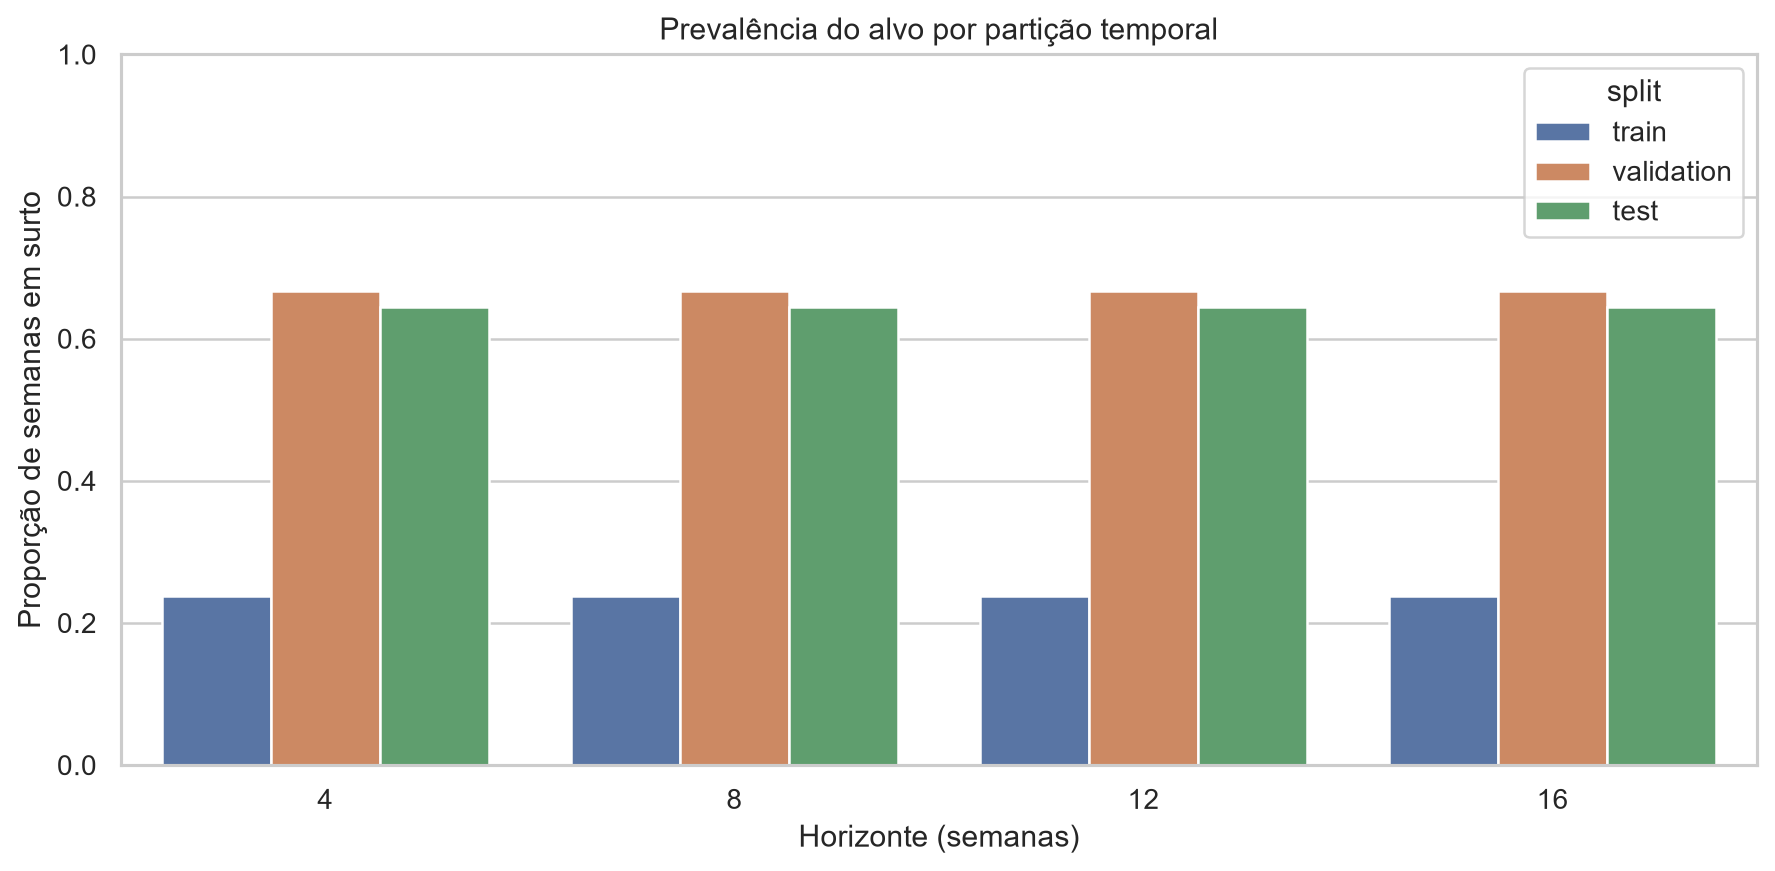

In [5]:
display(splits)
display(Image(filename=str(config.output_dir / 'figuras/prevalencia_particoes.png')))

## Resultados da previsão exata

,horizon,model_label,pr_auc,roc_auc,precision,recall_sensitivity,f2,false_alarms_per_year
1,4,Regressão logística,0.961885,0.920532,0.980000,0.731343,0.770440,0.501707
11,4,LSTM PyTorch,0.894476,0.801533,0.867647,0.880597,0.877976,4.515361
9,4,LSTM NumPy (BPTT),0.849648,0.680113,0.644231,1.000000,0.900538,18.563149
7,4,Baseline persistência,0.783885,0.743647,0.644231,1.000000,0.900538,18.563149
3,4,Random Forest,0.780938,0.602259,0.807692,0.313433,0.357143,2.508534
5,4,Baseline sazonal,0.625849,0.437475,0.647059,0.985075,0.891892,18.061442
23,8,LSTM PyTorch,0.927141,0.841065,0.652174,0.895522,0.833333,16.054615
13,8,Regressão logística,0.876466,0.782574,0.758621,0.656716,0.674847,7.023894
21,8,LSTM NumPy (BPTT),0.800126,0.634933,0.644231,1.000000,0.900538,18.563149
19,8,Baseline persistência,0.751458,0.695643,0.644231,1.000000,0.900538,18.563149


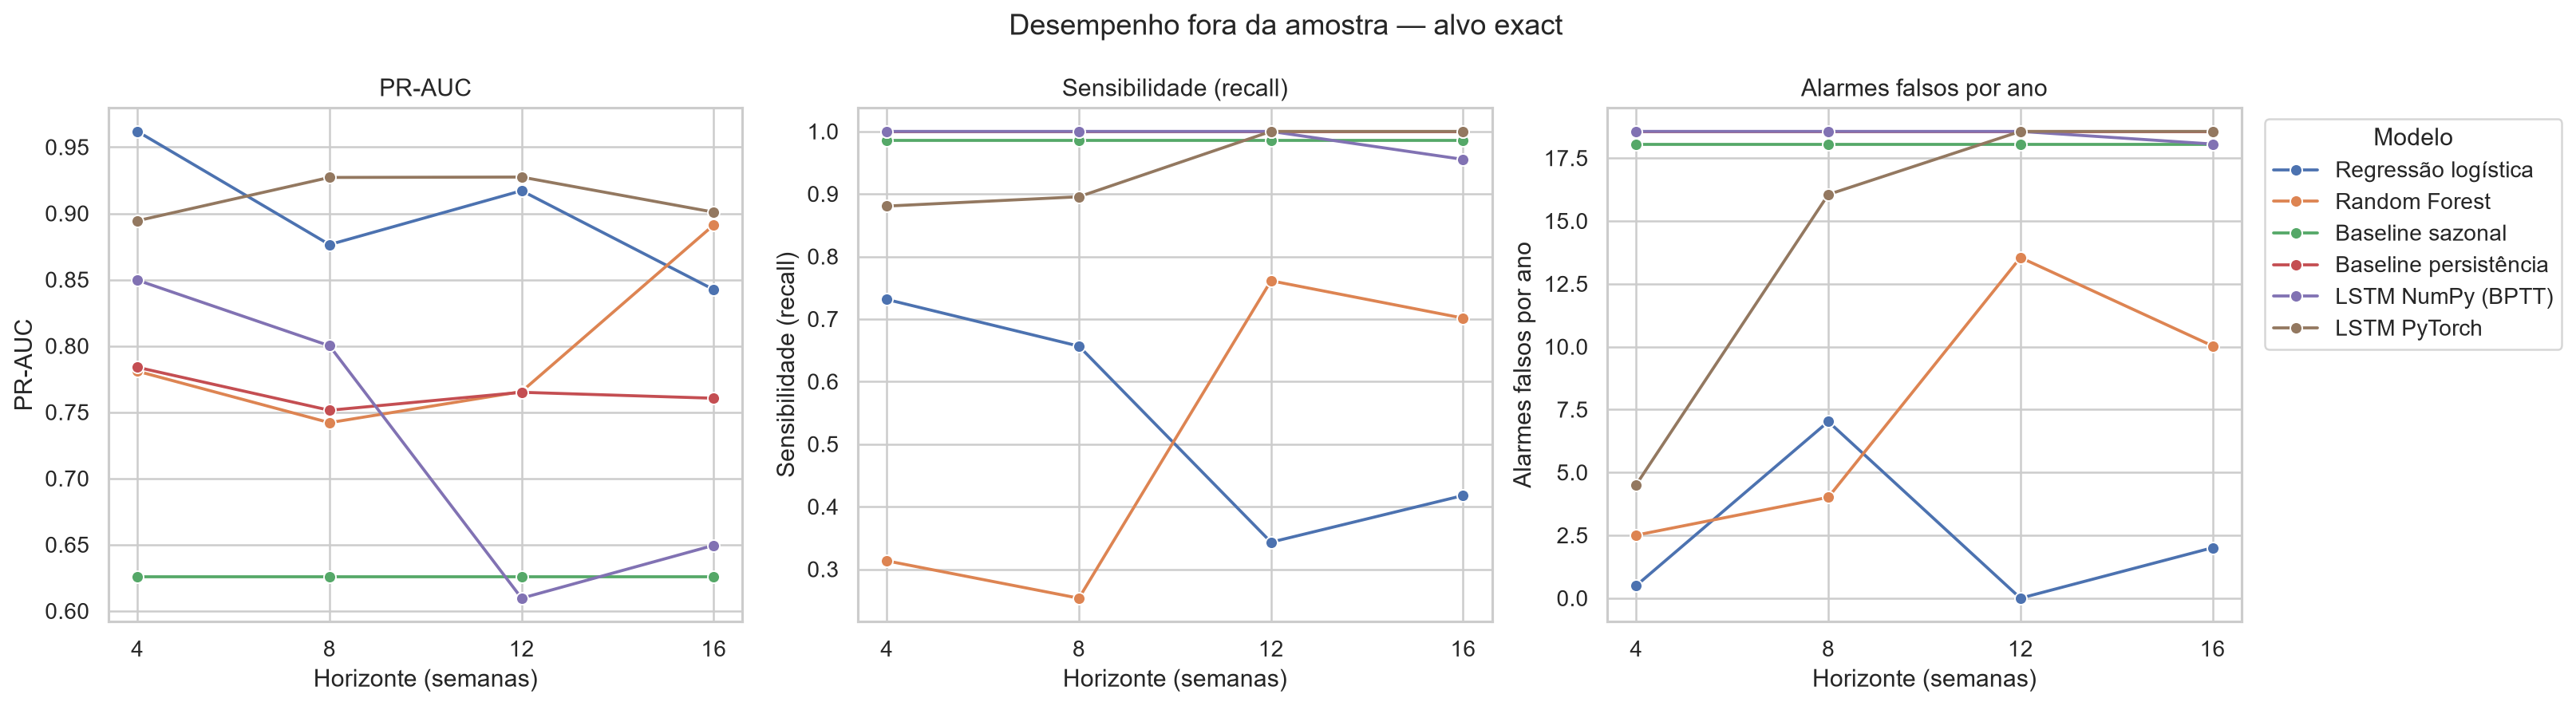

In [6]:
exact_test = metrics.query("target_kind == 'exact' and split == 'test'")
display(exact_test[['horizon','model_label','pr_auc','roc_auc','precision','recall_sensitivity','f2','false_alarms_per_year']]
        .sort_values(['horizon','pr_auc'], ascending=[True,False]))
display(Image(filename=str(config.output_dir / 'figuras/comparacao_exact.png')))

## Análise complementar em janela

,horizon,model_label,prevalence,pr_auc,recall_sensitivity,false_alarms_per_year
49,4,Regressão logística,0.750000,0.971208,0.974359,4.515361
59,4,LSTM PyTorch,0.750000,0.953357,0.871795,8.027308
57,4,LSTM NumPy (BPTT),0.750000,0.901141,1.000000,13.044375
55,4,Baseline persistência,0.750000,0.891026,1.000000,13.044375
51,4,Random Forest,0.750000,0.783341,0.602564,7.023894
53,4,Baseline sazonal,0.750000,0.737222,1.000000,13.044375
61,8,Regressão logística,0.846154,0.995139,0.920455,0.000000
71,8,LSTM PyTorch,0.846154,0.971038,1.000000,8.027308
67,8,Baseline persistência,0.846154,0.949915,1.000000,8.027308
69,8,LSTM NumPy (BPTT),0.846154,0.919443,0.965909,8.027308


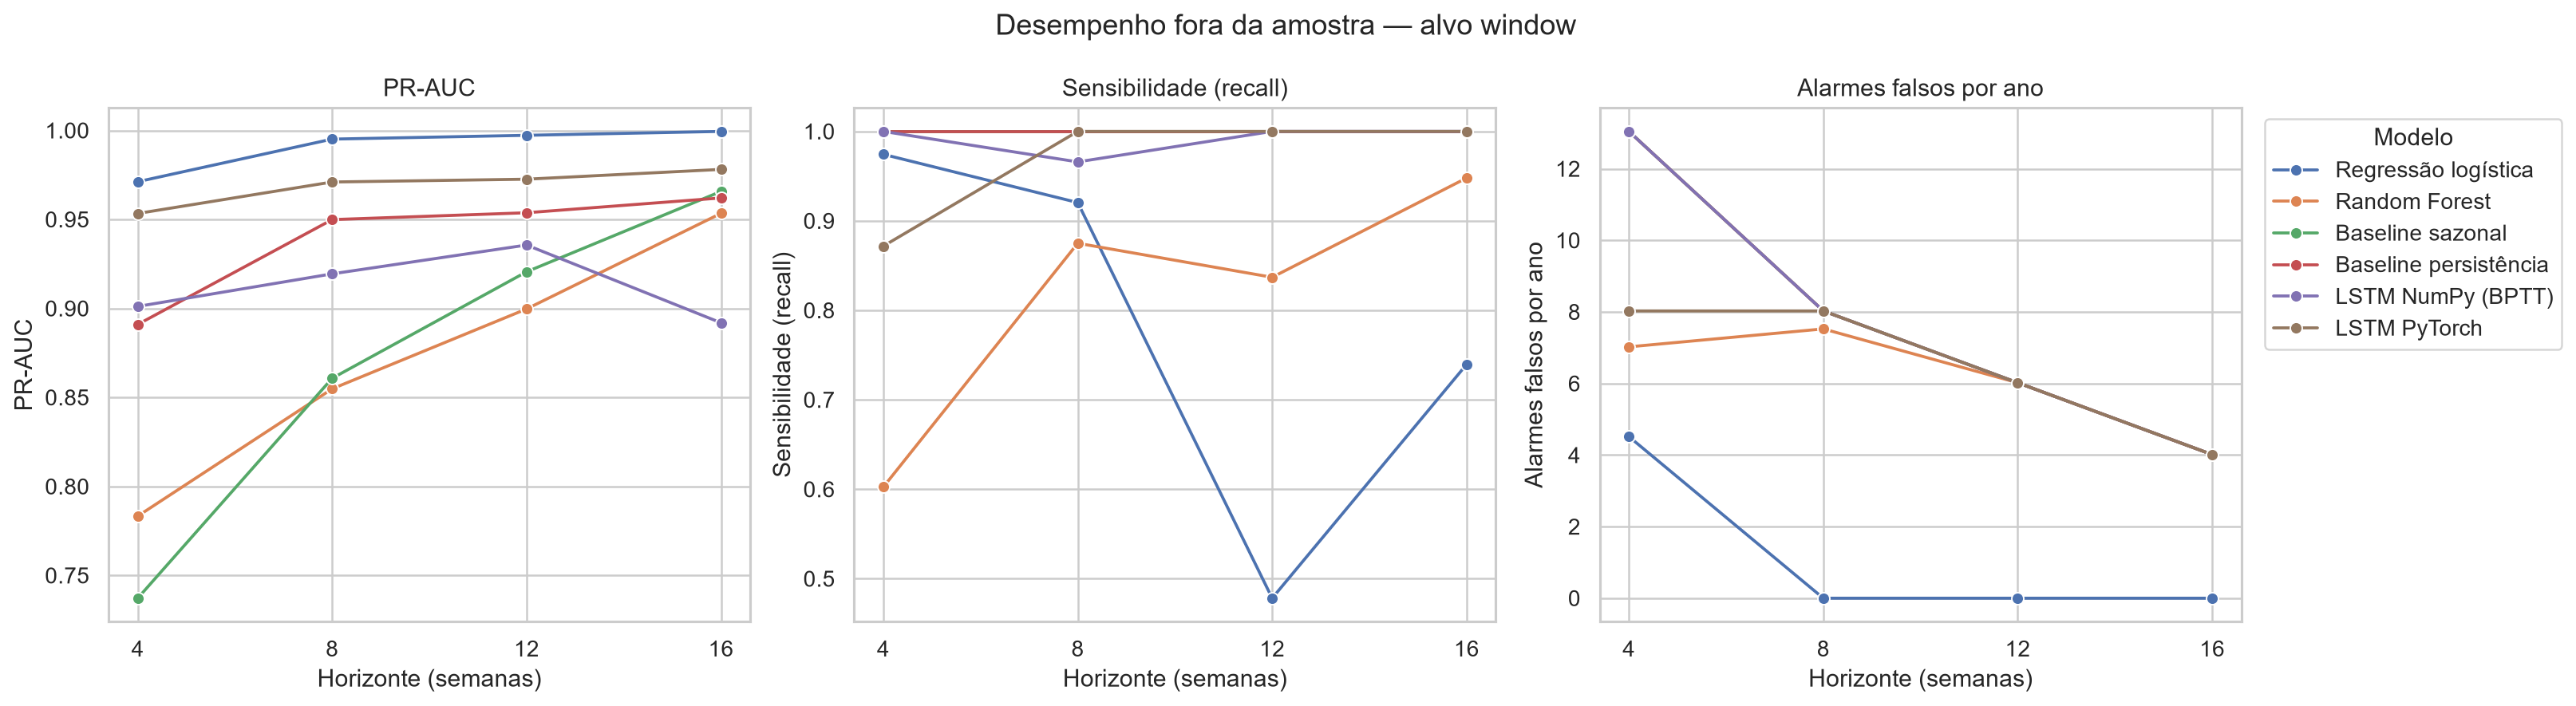

In [7]:
window_test = metrics.query("target_kind == 'window' and split == 'test'")
display(window_test[['horizon','model_label','prevalence','pr_auc','recall_sensitivity','false_alarms_per_year']]
        .sort_values(['horizon','pr_auc'], ascending=[True,False]))
display(Image(filename=str(config.output_dir / 'figuras/comparacao_window.png')))

## Explicabilidade do LSTM PyTorch

Integrated Gradients e Occlusion são calculados somente no teste. O vetor zero no espaço padronizado representa a média do treino. As atribuições explicam a saída do modelo; não estabelecem causalidade epidemiológica.

In [8]:
for horizon in config.horizons:
    path = config.output_dir / 'exact' / f'{horizon:02d}_semanas' / 'captum/integrated_gradients_features.csv'
    print()
    print(f'Horizonte {horizon} semanas')
    display(pd.read_csv(path).head(10))


Horizonte 4 semanas


,feature,mean_absolute_attribution,mean_signed_attribution
0,log_cases_lag_1,0.066150,0.066150
1,log_cases_lag_52,0.062907,-0.060850
2,log_cases_lag_2,0.050724,0.050724
3,log_cases_lag_4,0.040763,0.040763
4,ONI,0.036178,-0.001436
5,media_temperatura_semana,0.020012,0.001774
6,log_cases_lag_8,0.019512,0.019508
7,cases_mean_12,0.012346,-0.012060
8,week_sin,0.011572,0.003163
9,media_umidade_semana,0.008880,-0.006074



Horizonte 8 semanas


,feature,mean_absolute_attribution,mean_signed_attribution
0,log_cases_lag_1,0.041039,0.041039
1,log_cases_lag_52,0.039221,-0.037771
2,log_cases_lag_2,0.034850,0.034850
3,log_cases_lag_4,0.023483,0.023483
4,ONI,0.023441,0.002620
5,media_temperatura_semana,0.012052,0.001930
6,log_cases_lag_8,0.011611,0.011611
7,week_cos,0.008151,-0.000461
8,cases_mean_12,0.006941,-0.006780
9,cases_std_12,0.005792,-0.005043



Horizonte 12 semanas


,feature,mean_absolute_attribution,mean_signed_attribution
0,log_cases_lag_1,0.037124,0.037124
1,log_cases_lag_52,0.035669,-0.034346
2,log_cases_lag_2,0.031597,0.031597
3,ONI,0.023595,0.004467
4,log_cases_lag_4,0.020336,0.020336
5,media_temperatura_semana,0.015656,0.002858
6,log_cases_lag_8,0.009553,0.009553
7,week_cos,0.008332,-0.000776
8,cases_mean_12,0.007506,-0.007262
9,cases_std_12,0.004964,-0.004132



Horizonte 16 semanas


,feature,mean_absolute_attribution,mean_signed_attribution
0,log_cases_lag_52,0.033521,-0.032283
1,log_cases_lag_1,0.033198,0.033198
2,log_cases_lag_2,0.027211,0.027211
3,ONI,0.023985,0.006447
4,log_cases_lag_4,0.018191,0.018191
5,media_temperatura_semana,0.017836,0.003829
6,log_cases_lag_12,0.009898,-0.009825
7,cases_mean_12,0.009421,-0.009086
8,week_cos,0.008425,-0.000590
9,log_cases_lag_8,0.006290,0.006233


## Relatório e rastreabilidade

O relatório integral está em `reports/relatorio_revisao_metodologica.md`. Ele registra a formulação, as correções, as métricas, a explicabilidade, as limitações e as ameaças à validade. O notebook original permanece inalterado.